In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("hockey_teams_raw.csv")
print("    INFO of DATASET")
print("shape of dataset")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}")
print()
print("data types of columns")
print(df.dtypes)
print()
print(" Missing Values")
missing_df = pd.DataFrame({"Missing Count":df.isnull().sum(),"Missing %":(df.isnull().mean()*100).round(3)})
print(missing_df)
print()
cols_to_check = df.columns.drop("collected_at")
count=df.duplicated(subset=cols_to_check).sum()
duplicates = df.duplicated(
    subset=["Team Name", "Year"]
).sum()
print("Duplicate team-season records:", duplicates)
print("duplicated rows:", count )
print("    Summary Statistics")
print(df.describe())


    INFO of DATASET
shape of dataset
Total Rows: 582, Total Columns: 10

data types of columns
Team Name           str
Year              int64
Wins              int64
Losses            int64
OT Losses       float64
Win %           float64
GF                int64
GA                int64
+/-               int64
collected_at        str
dtype: object

 Missing Values
              Missing Count  Missing %
Team Name                 0      0.000
Year                      0      0.000
Wins                      0      0.000
Losses                    0      0.000
OT Losses               224     38.488
Win %                     0      0.000
GF                        0      0.000
GA                        0      0.000
+/-                       0      0.000
collected_at              0      0.000

Duplicate team-season records: 0
duplicated rows: 0
    Summary Statistics
              Year        Wins      Losses   OT Losses       Win %  \
count   582.000000  582.000000  582.000000  358.000000  582



1.The original dataset contains 582 records and 10 columns.The original missing-value analysis found 224 missing values in OT Losses, representing 38.49% of all rows. Other columns, including GF and GA, have no missing values in the original dataset.

2.To evaluate the preprocessing pipelines under missing-data conditions, the shared preprocessing.py script creates hockey_teams_missing.csv.The script randomly masks approximately 5% of the combined GF and GA cells, using random seed 12. This produces 58 missing entries from 1,164 possible GF and GA cells, approximately 4.98%.

3.The original hockey_teams_raw.csv remains unchanged.Missing GF and GA values are handled using median imputation inside the model preprocessing pipelines. The imputer is fitted only on training data to prevent test-data leakage.Wins, the regression target, is never modified by this experiment. The separate Win % classification target source is also preserved.

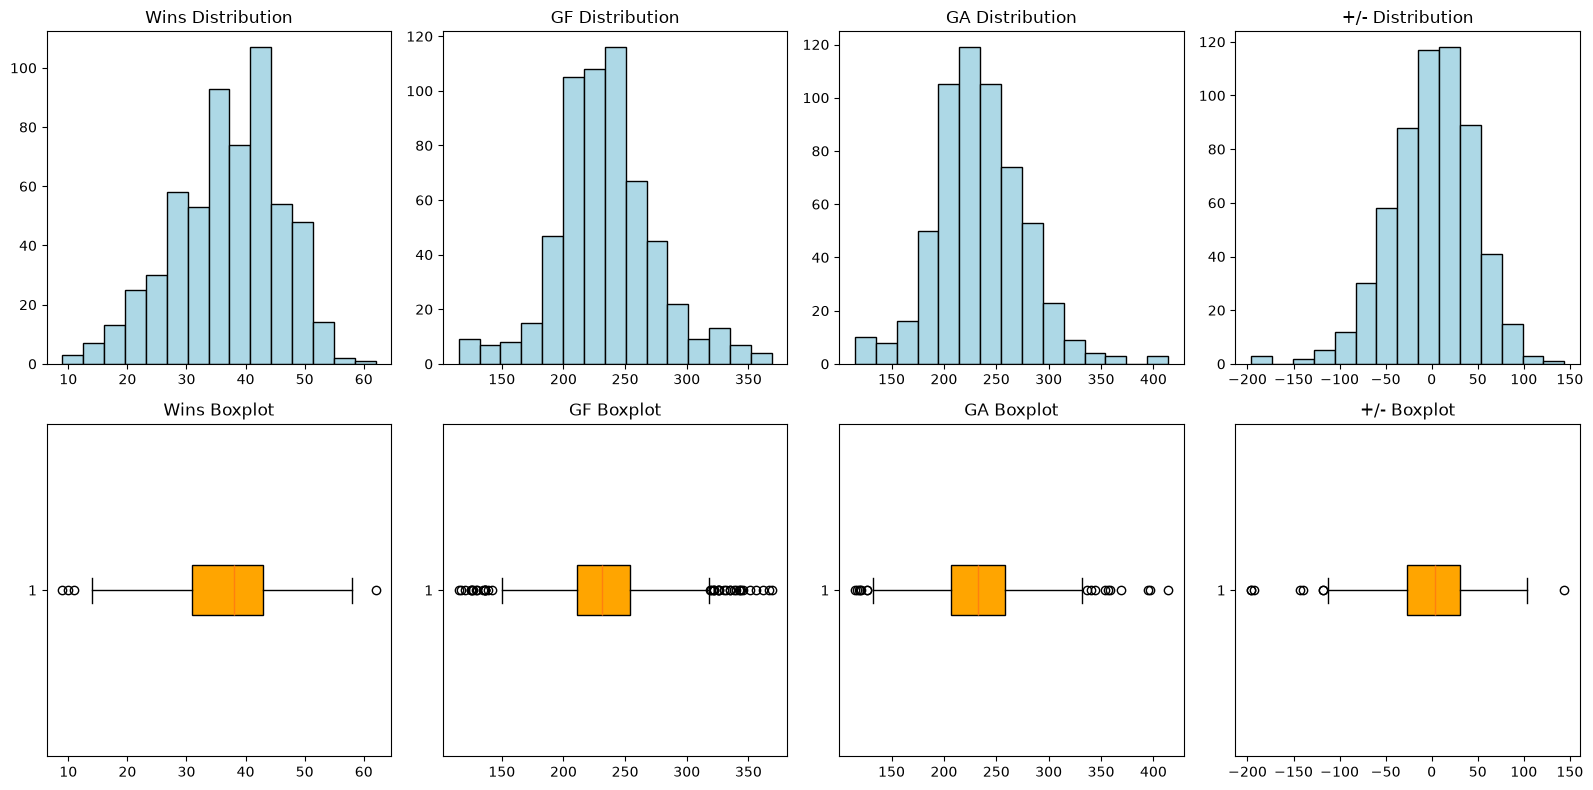

   Skewness Before Transformation
Wins   -0.39
GF      0.25
GA      0.32
+/-    -0.58
dtype: float64

    Skewness Comparison: Before vs After log1p
    Before Skewness  After log1p Skewness
GF             0.25                 -0.63
GA             0.32                 -0.53


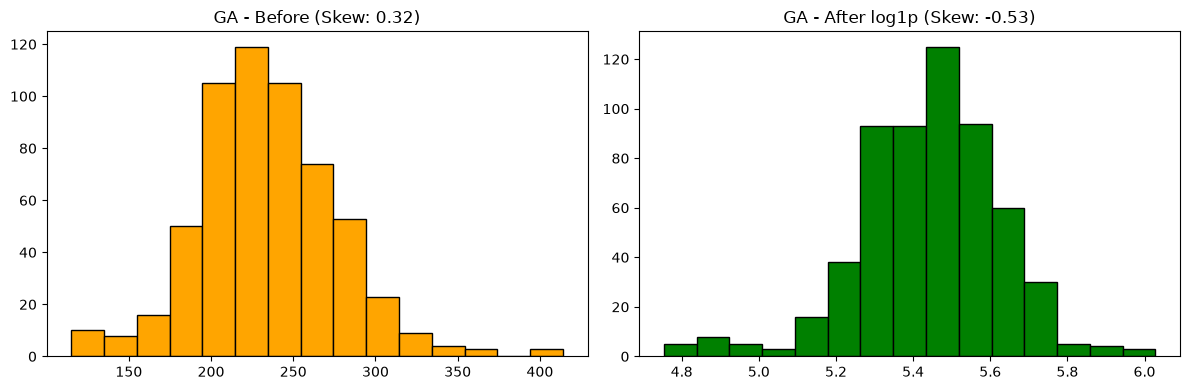

In [ ]:
numerical_cols=["Wins","GF","GA","+/-",]
fig, axes = plt.subplots(2, len(numerical_cols), figsize=(16, 8))
for i, col in enumerate(numerical_cols):
    # Top row is for Histogram graphs
    axes[0,i].hist(df[col].dropna(),bins=15,color="lightblue",edgecolor="black")
    axes[0, i].set_title(f"{col} Distribution")
    # Bottom row: for Boxplot graph's
    axes[1,i].boxplot(df[col].dropna(),orientation="horizontal",patch_artist=True,boxprops=dict(facecolor="orange"))
    axes[1, i].set_title(f"{col} Boxplot")
plt.tight_layout() # for adjusting space btw graphs
plt.show() #for displaying graphs
print("   Skewness Before Transformation")
skewness_before = df[numerical_cols].skew()
print(skewness_before.round(2))
print()
positive_col = ["GF", "GA"]
skewness_check = df[positive_col].copy()
for col in positive_col:     # Test log1p transformation to evaluate its effect on skewness
    skewness_check[f"{col}_log1p"] = np.log1p(skewness_check[col])
print("    Skewness Comparison: Before vs After log1p")
comparison = pd.DataFrame({
    "Before Skewness": [df["GF"].skew(), df["GA"].skew()],
    "After log1p Skewness": [skewness_check["GF_log1p"].skew(), skewness_check["GA_log1p"].skew()]}, index=positive_col)
print(comparison.round(2))
most_skewed = comparison["Before Skewness"].abs().idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df[most_skewed].dropna(), bins=15, color="orange",edgecolor="black")
axes[0].set_title(f"{most_skewed} - Before (Skew: {df[most_skewed].skew():.2f})")

axes[1].hist(skewness_check[f"{most_skewed}_log1p"].dropna(), bins=15, color="green",edgecolor='black')
axes[1].set_title(f"{most_skewed} - After log1p (Skew: {skewness_check[f'{most_skewed}_log1p'].skew():.2f})")
plt.tight_layout()
plt.show()

1. Generates histograms and boxplots for Wins, GF, GA, and +/- to examine their distributions. It calculates skewness and compares the original GF and GA distributions with a logarithmic (log1p) transformation.
2. Skewness helps identify asymmetrical distributions that may influence the behavior and interpretation of some regression models. Transformations should only be applied when appropriate, not automatically.
3.
Wins: approximately -0.39 (slight negative skew).
GF: approximately 0.25 (slight positive skew).
GA: approximately 0.32 (slight positive skew).
+/-: approximately -0.58 (moderate negative skew).

4. GF and GA already have relatively small skewness values, both within ±0.5. Applying log1p increased the absolute skewness of GF from 0.25 to 0.63 and GA from 0.32 to 0.53. Therefore, no log transformation was applied to the final features.

5. Linear models may benefit from appropriate transformations when feature relationships are nonlinear or residual assumptions are affected. Decision Trees and Random Forests are generally less sensitive to skewness because they split features using thresholds rather than assuming a linear relationship.

HOCKEY TEAM PERFORMANCE - REGRESSION TRAINING LOG
Random Seed: 12
Training Started: 2026-11-25 20:40:44.903898
Training Completed: 2026-11-25 20:40:45.904588

DATASET INFORMATION
Training Records: 462
Testing Records: 120
Training Years: 1990 - 2007
Testing Years: 2008 - 2011

FINAL REGRESSION TEST RESULTS
            Model   MAE    MSE  RMSE  R2 Score
Linear Regression 2.634 10.943 3.308    0.7636
    Decision Tree 3.042 14.392 3.794    0.6892
    Random Forest 2.295  8.296 2.880    0.8208

Baseline MAE: 7.090 wins


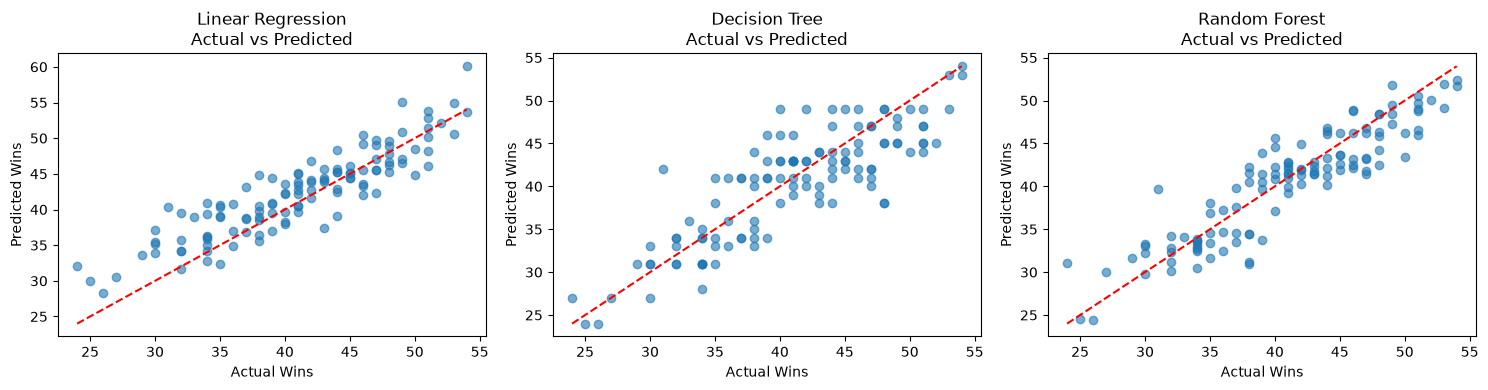

In [7]:
from datetime import datetime
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)
SEED = 12
df_reg = pd.read_csv("../data/hockey_teams_missing.csv")
df_sorted = df_reg.sort_values("Year").reset_index(drop=True)
split_idx = int(len(df_sorted) * 0.80)
cutoff_year = df_sorted.loc[split_idx, "Year"]
train_df = df_sorted[df_sorted["Year"] < cutoff_year].copy()
test_df = df_sorted[df_sorted["Year"] >= cutoff_year].copy()

x_features = ["Team Name", "Year", "GF", "GA", "+/-"]
y_target = "Wins"
x_train = train_df[x_features].copy()
x_test = test_df[x_features].copy()
y_train = train_df[y_target]
y_test = test_df[y_target]
# Define preprocessing
num_cols = ["Year", "GF", "GA", "+/-"]
cat_cols = ["Team Name"]
prep = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler())]), num_cols),("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
# Define regression models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        random_state=SEED ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=SEED )
}
# Train and evaluate models
results = []
predictions = {}
trained_models = {}
training_start = datetime.now()
for name, model in models.items():
    pipe = Pipeline([
        ("prep", clone(prep)),
        ("model", clone(model))])
    pipe.fit(x_train, y_train)
    y_pred = pipe.predict(x_test)
    trained_models[name] = pipe
    predictions[name] = y_pred
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results.append({
        "Model": name,
        "MAE": round(mae, 3),
        "MSE": round(mse, 3),
        "RMSE": round(rmse, 3),
        "R2 Score": round(r2, 4) })
training_end = datetime.now()
results_df = pd.DataFrame(results)
# predict the training mean
baseline_pred = np.full(len(y_test), y_train.mean())
baseline_mae = mean_absolute_error(y_test, baseline_pred)
# Print training log
print("=" * 60)
print("HOCKEY TEAM PERFORMANCE - REGRESSION TRAINING LOG")
print("=" * 60)
print("Random Seed:", SEED)
print("Training Started:", training_start)
print("Training Completed:", training_end)
print("\nDATASET INFORMATION")
print("Training Records:", len(x_train))
print("Testing Records:", len(x_test))
print("Training Years:",train_df["Year"].min(), "-", train_df["Year"].max())
print("Testing Years:", test_df["Year"].min(), "-", test_df["Year"].max())
print("\nFINAL REGRESSION TEST RESULTS")
print(results_df.to_string(index=False))
print(f"\nBaseline MAE: {baseline_mae:.3f} wins")
print("=" * 60)
# Actual vs Predicted plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, (name, y_pred) in enumerate(predictions.items()):
    axes[i].scatter(y_test, y_pred, alpha=0.6)
    axes[i].plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        "r--"
    )
    axes[i].set_title(f"{name}\nActual vs Predicted")
    axes[i].set_xlabel("Actual Wins")
    axes[i].set_ylabel("Predicted Wins")
plt.tight_layout()
plt.show()

1. Splits the dataset chronologically by "Year" (80% training, 20% testing), standardizes numerical features ("Year", "GF", "GA", "+/-") using training set statistics, encodes "Team Name" via One-Hot Encoding inside a scikit-learn Pipeline, and trains three regression models (Linear Regression, Decision Tree, and Random Forest) to predict seasonal "Wins".
2. Chronological splitting prevents future data leakage, fitting scalers and encoders strictly on training data avoids preprocessing leakage, and comparing linear against tree-based models helps evaluate which algorithm best captures team performance patterns.
3. Prints a structured regression training log (including timestamps, dataset split sizes, year ranges, and evaluation metrics: MAE, MSE, RMSE, and R² Score) and plots Actual vs. Predicted scatter charts for all three models to visually compare their prediction accuracy.

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
# Calculating VIF using training observations
# with complete numerical values
vif_features = ["Year", "GF", "GA", "+/-"]
vif_train = train_df[vif_features].dropna()
def calculate_vif(data):
    X = add_constant(data, has_constant="add")
    return pd.DataFrame({
        "Feature": X.columns,
        "VIF": [
            variance_inflation_factor(X.values, i)
            for i in range(X.shape[1])
        ]
    }).query("Feature != 'const'")
# VIF before dropping +/-
vif_before = calculate_vif(vif_train)
print("VIF BEFORE REMOVING +/-")
print(vif_before.to_string(index=False))
#  VIF after dropping +/-
vif_after = calculate_vif(
    vif_train[["Year", "GF", "GA"]]
)
print("\nVIF AFTER REMOVING +/-")
print(vif_after.to_string(index=False))
# Use the original full-feature Linear Regression
full_lr = trained_models["Linear Regression"]
full_pred = full_lr.predict(x_test)
#  Create a final Linear Regression pipeline without +/-
final_num_cols = ["Year", "GF", "GA"]
final_features = ["Team Name", "Year", "GF", "GA"]
prep_clean = ColumnTransformer([("num", Pipeline([("imp", SimpleImputer(strategy="median")),("sc", StandardScaler())]), final_num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), ["Team Name"])])
final_lr = Pipeline([("prep", prep_clean),("model", LinearRegression())])
# Fit the updated model on training data only
final_lr.fit(x_train[final_features], y_train)
clean_pred = final_lr.predict(x_test[final_features])
# Compare results before and after VIF
vif_model_comparison = pd.DataFrame({
    "Model": [ "Before VIF (with +/-)", "After VIF (without +/-)" ],
    "MAE": [ mean_absolute_error(y_test, full_pred), mean_absolute_error(y_test, clean_pred) ],
    "RMSE": [ np.sqrt(mean_squared_error(y_test, full_pred)),  np.sqrt(mean_squared_error(y_test, clean_pred))],
    "R2": [r2_score(y_test, full_pred), r2_score(y_test, clean_pred)]})
print("\nLINEAR REGRESSION COMPARISON")
print(vif_model_comparison.round(4).to_string(index=False))
# Final VIF comparison table
vif_summary = pd.DataFrame({
    "Feature": ["Year", "GF", "GA", "+/-"],
    "Before VIF": [
        vif_before.set_index("Feature").loc[f, "VIF"]
        for f in ["Year", "GF", "GA", "+/-"]
    ],
    "After VIF": [
        vif_after.set_index("Feature").loc[f, "VIF"]
        if f != "+/-" else np.nan 
        for f in ["Year", "GF", "GA", "+/-"] ]})

print("\nFINAL VIF SUMMARY")
print(vif_summary.round(3).to_string(index=False))


c:\Users\FLH\anaconda3\Lib\site-packages\statsmodels\stats\outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


VIF BEFORE REMOVING +/-
Feature      VIF
   Year 1.104947
     GF      inf
     GA      inf
    +/-      inf

VIF AFTER REMOVING +/-
Feature      VIF
   Year 1.104947
     GF 1.282414
     GA 1.273582

LINEAR REGRESSION COMPARISON
                  Model    MAE   RMSE     R2
  Before VIF (with +/-) 2.6342 3.3081 0.7636
After VIF (without +/-) 3.0227 3.8221 0.6845

FINAL VIF SUMMARY
Feature  Before VIF  After VIF
   Year       1.105      1.105
     GF         inf      1.282
     GA         inf      1.274
    +/-         inf        NaN


1. Calculates the Variance Inflation Factor for numerical features using complete training observations. It compares the features before and after removing goal differential (+/-), and evaluates Linear Regression using both feature sets.
2. Goal differential is calculated directly from GF and GA: +/- = GF - GA
Including all three creates perfect multicollinearity in the original complete observations. This can make Linear Regression coefficients non-unique and difficult to interpret.

3. Before removing +/-, the VIF values of GF, GA, and +/- are infinite. After removing +/-, the VIF values become approximately 1.3, demonstrating a substantial reduction in multicollinearity.
4. VIF is a diagnostic for feature redundancy, not a technique that automatically improves predictive accuracy. Removing +/- makes the individual coefficients more identifiable and interpretable. For complete data, the predictive performance can remain unchanged. For the missing-data experiment, the before-and-after metrics must be compared because independent imputation can affect the exact relationship.
5. The final Linear Regression pipeline uses Team Name, Year, GF, and GA, excluding +/-. This addresses the multicollinearity identified through VIF while retaining the underlying information contained in goals scored and goals allowed.

In [ ]:
final_results_df = results_df.copy()
# Replace the full-feature Linear Regression metrics
# with the VIF-reduced final Linear Regression metrics.
row = final_results_df["Model"] == "Linear Regression"
final_results_df.loc[row, "MAE"] = round(mean_absolute_error(y_test, clean_pred), 3)
final_results_df.loc[row, "MSE"] = round(mean_squared_error(y_test, clean_pred), 3)
final_results_df.loc[row, "RMSE"] = round(np.sqrt(mean_squared_error(y_test, clean_pred)), 3)
final_results_df.loc[row, "R2 Score"] = round( r2_score(y_test, clean_pred), 4)
print("FINAL MODEL COMPARISON AFTER VIF")
print(final_results_df.to_string(index=False))
best_model = final_results_df.loc[final_results_df["MAE"].idxmin()]
print("\nBest Model:", best_model["Model"])
print("Best MAE:", best_model["MAE"])

FINAL MODEL COMPARISON AFTER VIF
            Model   MAE    MSE  RMSE  R2 Score
Linear Regression 3.023 14.609 3.822    0.6845
    Decision Tree 3.042 14.392 3.794    0.6892
    Random Forest 2.295  8.296 2.880    0.8208

Best Model: Random Forest
Best MAE: 2.295


In [6]:
import pandas as pd
# Create a copy to preserve the original dataset
df_cleaned = df.copy()
df_cleaned["Team Name"] = df_cleaned["Team Name"].str.strip()
# Convert collected_at to datetime
df_cleaned["collected_at"] = pd.to_datetime(df_cleaned["collected_at"], errors="coerce")
numeric_cols = ["Year", "Wins", "Losses", "OT Losses","Win %", "GF", "GA", "+/-"]
for col in numeric_cols:
    df_cleaned[col] = pd.to_numeric(df_cleaned[col], errors="coerce")
# Historical missing OT Losses values are treated as zero
# because this standings category was not separately recorded
# before the 1999-2000 NHL season.
df_cleaned["OT Losses"] = (df_cleaned["OT Losses"].fillna(0).astype(int))
# Check duplicates while ignoring collection timestamps
cols_to_check = df_cleaned.columns.drop("collected_at")
print("Duplicates before cleaning:",df_cleaned.duplicated(subset=cols_to_check).sum())
# Remove duplicate records if any
df_cleaned = df_cleaned.drop_duplicates(subset=cols_to_check).reset_index(drop=True)
# Display missing values
print("\nMissing values after cleaning:")
print(df_cleaned.isnull().sum())
# Display final shape
print("\nFinal Shape:", df_cleaned.shape)
# Save cleaned dataset in the data folder
df_cleaned.to_csv("../data/hockey_teams_cleaned.csv",index=False)
print("\nCleaned dataset saved successfully!")

Duplicates before cleaning: 0

Missing values after cleaning:
Team Name       0
Year            0
Wins            0
Losses          0
OT Losses       0
Win %           0
GF              0
GA              0
+/-             0
collected_at    0
dtype: int64

Final Shape: (582, 10)

Cleaned dataset saved successfully!


1.Cleans the raw dataset by filling missing "OT Losses" with "0", removing extra spaces from "Team Name", fixing data types (converting dates to datetime and stats to numbers), removing duplicate rows, and saving the final dataset as "hockey_teams_cleaned.csv".

2.Raw scraped data often contains blank cells, extra spaces, or text-formatted numbers that can cause errors during analysis and model training. Cleaning these issues ensures the dataset is consistent and ready for machine learning.

3.Confirms that there are "0" missing values remaining across all columns, prints the final cleaned dataset shape (rows and columns), and verifies that "hockey_teams_cleaned.csv" was successfully saved.